## 2. Réseau du neurones sur Iris

*Objectif: Classifier les fleurs Iris en 3 classes avec un MLP simple*

##### Etape 1: Importer les libraires

In [1]:
#importing libraries from libs.py

from libs import *        # np, pd, plt, tf, keras, layers, train_test_split, ...

tf.keras.utils.set_random_seed(42)

##### Etape 2: Charger le dataset Iris

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data # 4 features
y = iris.target #classes 0, 1, 2

print("Dimensions X: ", X.shape)
print("Dimensions y: ", y.shape)

Dimensions X:  (150, 4)
Dimensions y:  (150,)


##### Etape 3: Visualiser les 5 premières lignes

In [3]:
print("Exemples de X :\n", X[:5])
print("Exemples de y :\n", y[:5])

Exemples de X :
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
Exemples de y :
 [0 0 0 0 0]


##### Etape 4: Split train/test
```
On sépare avant tout calcul de statistiques. L'option stratify = y garde les 3 classes à égalité dans les deux jeux
```

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, stratify = y, random_state=42)

print("Taille train : ", X_train.shape)
print("taille test : ", X_test.shape)

Taille train :  (120, 4)
taille test :  (30, 4)


##### Etape 5: One-Hot Encoding pour les sorties

In [5]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)
y_train = encoder.fit_transform(y_train.reshape(-1, 1))
y_test = encoder.transform(y_test.reshape(-1, 1))
print("Sortie encodées :\n", y_train[:5])

Sortie encodées :
 [[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]


##### Etape 6: Normaliser les features (standardisation)

```
Le scaler est ajusté sur le train uniquement : les test est seulement transformé
```

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Features normalisées :\n", X_train[:5])


Features normalisées :
 [[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


##### Etape 7: Construire le modèle MLP

In [7]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

# model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

###### Layer

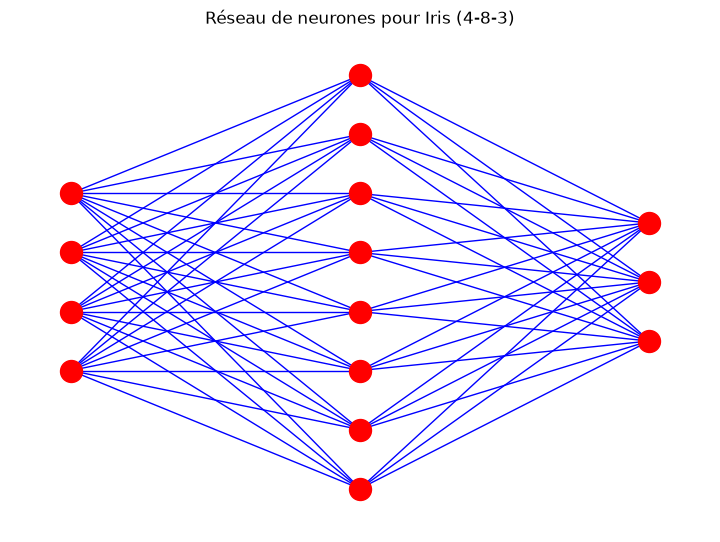

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

layer_sizes = [4, 8, 3]

G = nx.DiGraph()
pos = {}
layer_positions = []

for l, n_neurons in enumerate(layer_sizes):
    layer_pos = []
    offset = (n_neurons - 1) / 2              # centre each layer vertically
    for i in range(n_neurons):
        node_id = f"L{l}N{i}"
        G.add_node(node_id, layer=l)
        pos[node_id] = (l, offset - i)        # neurons in columns
        layer_pos.append(node_id)
    layer_positions.append(layer_pos)         # <-- fix: node names, not `layers`

for l in range(len(layer_sizes) - 1):
    for src in layer_positions[l]:
        for dst in layer_positions[l + 1]:
            G.add_edge(src, dst)

plt.figure(figsize=(7, 5))
nx.draw(G, pos, with_labels=False, node_size=250,
        node_color="red", edge_color="blue", arrows=False)
plt.title("Réseau de neurones pour Iris (4-8-3)", fontsize=12)
plt.show()

##### Etape 8: Compiler le modèle

In [9]:
# Utiliser: optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

##### Etape 9: Entraîner le modèle

##### Parameters: epochs, batch_size, validation
### Epochs

An epoch is one complete pass of the model through the entire training dataset.

Example:

Dataset = 1,000 records
epochs = 100

The model will see all 1,000 records 100 times during training.

Purpose:

Allows the model to gradually learn patterns from the data.
Too few epochs may cause underfitting.
Too many epochs may cause overfitting.
### Batch Size
Batch size is the number of training examples processed before the model updates its weights.
Example:

Dataset = 1,000 records
batch_size = 5

The model processes:

Records 1-5   → update weights
Records 6-10  → update weights
Records 11-15 → update weights
...

Number of batches:

1000 ÷ 5 = 200 batches

Purpose:

Controls memory usage and training speed.
Small batch sizes learn more frequently but train slower.
Large batch sizes train faster but require more memory.
### Validation (Validation Split)
Validation data is a portion of the dataset reserved for evaluating the model during training.

Example:

validation_split=0.1
means:

10% Validation Data
90% Training Data
For a dataset of 1,000 records:

900 rows → Training
100 rows → Validation
The model learns from the 900 training rows and is tested on the 100 validation rows after each epoch.

In [10]:
# Parametètres

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=5,
    validation_split=0.1
)

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.6389 - loss: 0.8449 - val_accuracy: 0.6667 - val_loss: 0.8814
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7222 - loss: 0.7955 - val_accuracy: 0.6667 - val_loss: 0.8358
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7037 - loss: 0.7498 - val_accuracy: 0.6667 - val_loss: 0.7926
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7222 - loss: 0.7077 - val_accuracy: 0.6667 - val_loss: 0.7534
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7407 - loss: 0.6687 - val_accuracy: 0.6667 - val_loss: 0.7191
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7685 - loss: 0.6339 - val_accuracy: 0.6667 - val_loss: 0.6890
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7778 - loss: 0.6033 - val_accuracy: 0.6667 - val_loss: 0.6631
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7778 - loss: 0.5764 - val_accuracy: 0.6667 - 

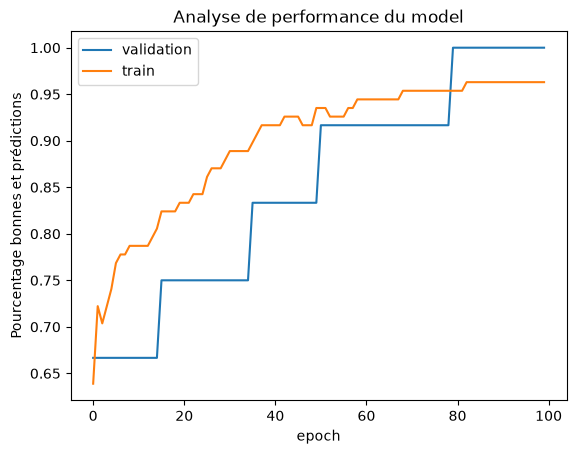

In [11]:
# plot

plt.plot(history.history["val_accuracy"])
plt.plot(history.history["accuracy"])
plt.title("Analyse de performance du model")
plt.xlabel("epoch")
plt.ylabel("Pourcentage bonnes et prédictions")
plt.legend(["validation", "train"])

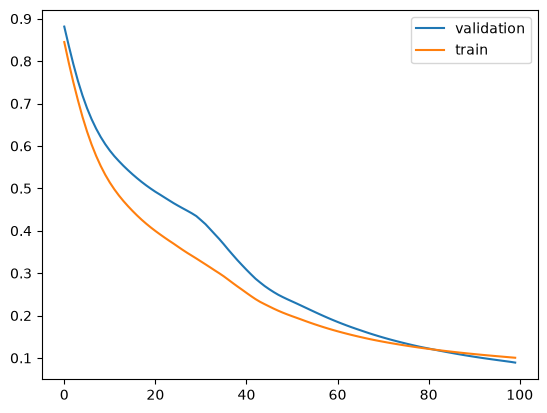

In [12]:
# # La fonction d'erreur est croissante sur les epoch
plt.plot(history.history["val_loss"])
plt.plot(history.history["loss"])
plt.legend(["validation", "train"])

##### Etape 10: Evaluer le modèle sur le test set

In [13]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy*100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9333 - loss: 0.1620
Test Accuracy: 93.33%


#### Exercice : Augmenter le score pour atteindre entre 85 et 90%

Analyser vos données pour le sur-apprentissage

##### Etape 11: Visualiser la prédiction pour quelques exemples

In [14]:
predictions = model.predict(X_test)
print("Predictions : \n", predictions[:5].round(3))
print("Classes prédites :", np.argmax(predictions, axis=1)[:20])
print("Vraies classes : ", np.argmax(y_test, axis=1)[:20])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
Predictions : 
 [[0.998 0.002 0.   ]
 [0.001 0.206 0.793]
 [0.043 0.948 0.009]
 [0.016 0.978 0.007]
 [0.999 0.001 0.   ]]
Classes prédites : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2]
Vraies classes :  [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2]


In [15]:
y_true  = np.argmax(y_test, axis=1)
y_pred = np.argmax(predictions, axis=1)

df = pd.DataFrame(scaler.inverse_transform(X_test), columns=iris.feature_names).round(1)

df["True_Class"]=y_true
df["Predicted_Class"]=y_pred
df.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),True_Class,Predicted_Class
0,4.4,3.0,1.3,0.2,0,0
1,6.1,3.0,4.9,1.8,2,2
2,4.9,2.4,3.3,1.0,1,1
3,5.0,2.3,3.3,1.0,1,1
4,4.4,3.2,1.3,0.2,0,0


##### Etape 12: Matrice de confusion

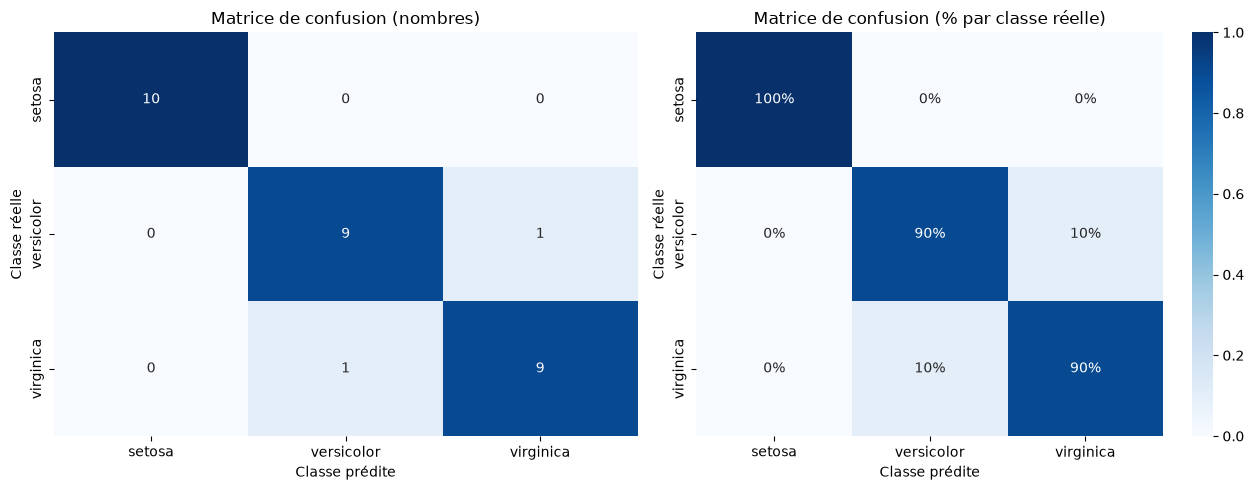

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [16]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

class_names = list(iris.target_names)          # ['setosa', 'versicolor', 'virginica']

y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)        # % par classe réelle

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=class_names, yticklabels=class_names, cbar=False)
axes[0].set_title("Matrice de confusion (nombres)")

sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Blues", ax=axes[1],
            xticklabels=class_names, yticklabels=class_names, vmin=0, vmax=1)
axes[1].set_title("Matrice de confusion (% par classe réelle)")

for ax in axes:
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")

plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))


##### Etape 13: Exemple de prédiction sur de nouvelles fleurs

In [17]:
# Mesures en cm : sepal length, sepal width, petal length, petal width
new_flowers = np.array([
    [5.1, 3.5, 1.4, 0.2],   # ressemble à une setosa
    [5.9, 3.0, 4.2, 1.5],   # ressemble à une versicolor
    [6.5, 3.0, 5.5, 1.8],   # ressemble à une virginica
])

# Même normalisation que pour l'entraînement (scaler ajusté sur le train)
new_scaled = scaler.transform(new_flowers)

proba = model.predict(new_scaled, verbose=0)
pred = np.argmax(proba, axis=1)

result = pd.DataFrame(new_flowers, columns=iris.feature_names)
result["Classe prédite"] = [class_names[i] for i in pred]
result["Confiance"] = (proba.max(axis=1) * 100).round(1).astype(str) + " %"
result


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Classe prédite,Confiance
0,5.1,3.5,1.4,0.2,setosa,99.8 %
1,5.9,3.0,4.2,1.5,versicolor,80.4 %
2,6.5,3.0,5.5,1.8,virginica,88.8 %


#### Conclusion

- **Objectif :** classifier les fleurs Iris en 3 classes (setosa, versicolor, virginica) à partir de 4 mesures, avec un MLP simple (4-8-3, 67 paramètres).
- **Préparation des données :** split train/test stratifié (80 % / 20 %), standardisation ajustée sur le train uniquement, sorties encodées en one-hot.
- **Résultat :** lors de l'exécution, le modèle atteint **93,33 % de précision sur le test set** (28 prédictions correctes sur 30). La matrice de confusion montre où se situent les erreurs : sur Iris, elles concernent généralement versicolor et virginica, dont les mesures se chevauchent, alors que setosa est facilement séparable.
- **Limites :** le jeu de test ne contient que 30 fleurs, donc chaque erreur pèse 3,3 points de précision. Le score peut varier selon le split et l'initialisation, et la validation pendant l'entraînement (12 exemples) reste très bruitée.
- **Pistes d'amélioration :** validation croisée pour une estimation plus fiable, comparaison avec une régression logistique comme référence, variation du nombre de neurones ou d'epochs avec `EarlyStopping`.
